# 04 - Attention-Based Seq2Seq LSTM for Telugu Text Correction
**IIIT Nagpur — Department of Computer Science & Engineering**  
**5th Semester Mini Project:** Automatic Text Correction for Low-Resource Languages (Telugu)

This notebook trains a character-level encoder-decoder with attention on the project's synthetic Telugu correction pairs. It uses the available training data more fully, includes aligned word-merge examples for spacing errors, masks padded input positions, selects the best validation checkpoint, and checks generated corrections against the Telugu vocabulary.

The model remains a word-level spelling corrector at inference. It preserves in-vocabulary words and does not claim to fix grammar or sentence-level semantic errors.

In [11]:
# Install required dependencies
%pip install -q torch jiwer sacrebleu rapidfuzz indic-nlp-library pandas matplotlib seaborn tqdm

import os
import sys
import re
import json
import time
import random
import unicodedata
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import jiwer
import sacrebleu

# Reproducibility seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set Telugu Unicode supported font for Matplotlib
plt.rcParams['font.family'] = 'Nirmala UI'
plt.rcParams['axes.unicode_minus'] = False

print(f"✅ PyTorch Version : {torch.__version__}")
print(f"✅ Compute Device  : {DEVICE}")


Note: you may need to restart the kernel to use updated packages.
✅ PyTorch Version : 2.14.1+cpu
✅ Compute Device  : cpu



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## 1. Attention-Based Character Seq2Seq Model

The encoder reads each noisy Telugu word as a sequence of Unicode code points. The decoder uses attention over the encoder's non-padding states while generating the correction. This avoids forcing the entire word through one final encoder state and prevents padding positions from influencing the encoded representation.

The task is trained on noisy-to-clean word pairs, plus examples where two clean words were joined by a synthetic missing-space error.

---
## 2. Dataset Ingestion & Character Vocabulary

The notebook loads the existing project train, validation, and test files. The character vocabulary is built from the complete training split only; validation and test data are not used to define it.

In [12]:
def find_data_file(subpath: str) -> Path:
    candidates = [
        Path("data") / subpath,
        Path("../data") / subpath,
        Path("notebook_data") / subpath,
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(f"Could not find {subpath}. Run this notebook from Notebooks or its parent folder.")

train_file = find_data_file("synthetic/train.json")
val_file = find_data_file("synthetic/val.json")
test_file = find_data_file("synthetic/test.json")
vocab_file = find_data_file("processed/telugu_vocab.json")

with train_file.open("r", encoding="utf-8") as file:
    train_data = json.load(file)
with val_file.open("r", encoding="utf-8") as file:
    val_data = json.load(file)
with test_file.open("r", encoding="utf-8") as file:
    test_data = json.load(file)
with vocab_file.open("r", encoding="utf-8") as file:
    vocab_dict = json.load(file)

vocab_set = set(vocab_dict)
print(f"Data directory: {train_file.parent.resolve()}")
print(f"Loaded {len(train_data):,} train, {len(val_data):,} validation, and {len(test_data):,} test sentence pairs.")
print(f"Loaded {len(vocab_set):,} words in the Telugu vocabulary.")

SPECIAL_TOKENS = ["<pad>", "<sos>", "<eos>", "<unk>"]
chars_set = set()
for item in train_data:
    chars_set.update(item["input"])
    chars_set.update(item["target"])

VOCAB = SPECIAL_TOKENS + sorted(chars_set)
char2idx = {char: index for index, char in enumerate(VOCAB)}
idx2char = {index: char for char, index in char2idx.items()}
PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = range(4)
print(f"Character vocabulary size: {len(VOCAB)}")
print(f"Sample Telugu characters: {VOCAB[4:20]}")

Data directory: D:\Desktop\nlp--share\Notebooks\data\synthetic
Loaded 60,000 train, 7,500 validation, and 7,500 test sentence pairs.
Loaded 100,000 words in the Telugu vocabulary.
Character vocabulary size: 231
Sample Telugu characters: [' ', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0']


In [13]:
MAX_WORD_LEN = 48
MAX_CHAR_CONTENT = MAX_WORD_LEN - 2
MAX_ERROR_PAIRS = 60000
CLEAN_TO_ERROR_RATIO = 0.30


def extract_word_pairs(sentence_pairs):
    pairs = []
    for record in sentence_pairs:
        noisy_words = record["input"].split()
        clean_words = record["target"].split()
        error_type = str(record.get("error_type", ""))

        if "space" in error_type and len(noisy_words) < len(clean_words):
            noisy_index = 0
            clean_index = 0
            while noisy_index < len(noisy_words) and clean_index < len(clean_words):
                if (clean_index + 1 < len(clean_words)
                        and noisy_words[noisy_index] == clean_words[clean_index] + clean_words[clean_index + 1]):
                    source = noisy_words[noisy_index]
                    target = clean_words[clean_index] + " " + clean_words[clean_index + 1]
                    pairs.append((source, target))
                    noisy_index += 1
                    clean_index += 2
                else:
                    pairs.append((noisy_words[noisy_index], clean_words[clean_index]))
                    noisy_index += 1
                    clean_index += 1
        elif len(noisy_words) == len(clean_words):
            pairs.extend(zip(noisy_words, clean_words))

    return list(dict.fromkeys(
        (source, target) for source, target in pairs
        if source and target
        and len(source) <= MAX_CHAR_CONTENT
        and len(target) <= MAX_CHAR_CONTENT
    ))


all_train_word_pairs = extract_word_pairs(train_data)
all_val_word_pairs = extract_word_pairs(val_data)
error_pairs = list(dict.fromkeys((source, target) for source, target in all_train_word_pairs if source != target))
clean_pairs = list(dict.fromkeys((source, target) for source, target in all_train_word_pairs if source == target))
random.shuffle(error_pairs)
random.shuffle(clean_pairs)

selected_errors = error_pairs[:MAX_ERROR_PAIRS]
clean_limit = min(len(clean_pairs), max(1, int(len(selected_errors) * CLEAN_TO_ERROR_RATIO)))
selected_clean = clean_pairs[:clean_limit]
training_pairs = selected_errors + selected_clean
random.shuffle(training_pairs)

val_errors = list(dict.fromkeys((source, target) for source, target in all_val_word_pairs if source != target))
val_clean = list(dict.fromkeys((source, target) for source, target in all_val_word_pairs if source == target))
val_clean = val_clean[:min(len(val_clean), max(1, int(len(val_errors) * CLEAN_TO_ERROR_RATIO)))]
val_pairs = val_errors + val_clean

print(f"Unique training errors available: {len(error_pairs):,}")
print(f"Training word pairs: {len(training_pairs):,} ({len(selected_errors):,} changed, {len(selected_clean):,} unchanged)")
print(f"Validation word pairs: {len(val_pairs):,} ({len(val_errors):,} changed, {len(val_clean):,} unchanged)")
print(f"Training examples that include a space target: {sum(' ' in target for _, target in training_pairs):,}")


class WordSeqDataset(Dataset):
    def __init__(self, pairs, max_len=MAX_WORD_LEN):
        self.samples = []
        for source, target in pairs:
            src_ids = [SOS_IDX] + [char2idx.get(char, UNK_IDX) for char in source[:max_len - 2]] + [EOS_IDX]
            tgt_ids = [SOS_IDX] + [char2idx.get(char, UNK_IDX) for char in target[:max_len - 2]] + [EOS_IDX]
            self.samples.append((torch.tensor(src_ids, dtype=torch.long), torch.tensor(tgt_ids, dtype=torch.long)))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


def pad_collate_fn(batch):
    sources, targets = zip(*batch)
    sources = nn.utils.rnn.pad_sequence(sources, batch_first=True, padding_value=PAD_IDX)
    targets = nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=PAD_IDX)
    return sources, targets


BATCH_SIZE = 64
train_loader = DataLoader(WordSeqDataset(training_pairs), batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate_fn)
val_loader = DataLoader(WordSeqDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)
print(f"DataLoaders ready: {len(train_loader):,} training batches and {len(val_loader):,} validation batches.")

Unique training errors available: 64,002
Training word pairs: 78,000 (60,000 changed, 18,000 unchanged)
Validation word pairs: 13,211 (10,163 changed, 3,048 unchanged)
Training examples that include a space target: 5,387
DataLoaders ready: 1,219 training batches and 207 validation batches.


---
## 4. Encoder, Attention Decoder, and Training

The encoder packs each batch using the true source lengths, so padded characters do not alter its final states. Additive attention lets the decoder focus on the relevant input characters. Training uses a lower learning rate, a scheduled teacher-forcing ratio, validation-based learning-rate reduction, early stopping, and a saved best checkpoint.

In [14]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim=96, hidden_dim=192, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True)

    def forward(self, src):
        lengths = src.ne(PAD_IDX).sum(dim=1).cpu()
        embedded = self.dropout(self.embedding(src))
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, (hidden, cell) = self.lstm(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        return outputs, hidden, cell


class AttentionDecoder(nn.Module):
    def __init__(self, vocab_size, emb_dim=96, hidden_dim=192, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)
        self.attn_encoder = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.attn_decoder = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.attn_score = nn.Linear(hidden_dim, 1, bias=False)
        self.lstm = nn.LSTM(emb_dim + hidden_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim * 2, vocab_size)

    def forward(self, token, hidden, cell, encoder_outputs, src_mask):
        embedded = self.dropout(self.embedding(token))
        query = hidden[-1].unsqueeze(1)
        scores = self.attn_score(torch.tanh(
            self.attn_encoder(encoder_outputs) + self.attn_decoder(query)
        )).squeeze(-1)
        scores = scores.masked_fill(~src_mask, torch.finfo(scores.dtype).min)
        attention = torch.softmax(scores, dim=-1)
        context = torch.bmm(attention.unsqueeze(1), encoder_outputs)
        decoder_input = torch.cat((embedded, context), dim=-1)
        output, (hidden, cell) = self.lstm(decoder_input, (hidden, cell))
        logits = self.output(torch.cat((output, context), dim=-1).squeeze(1))
        return logits, hidden, cell


class AttentiveSeq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, trg, teacher_forcing_ratio=0.7):
        batch_size, target_length = trg.shape
        encoder_outputs, hidden, cell = self.encoder(src)
        src_mask = src.ne(PAD_IDX)
        outputs = torch.zeros(batch_size, target_length, len(VOCAB), device=src.device)
        decoder_input = trg[:, :1]

        for step in range(1, target_length):
            logits, hidden, cell = self.decoder(
                decoder_input, hidden, cell, encoder_outputs, src_mask
            )
            outputs[:, step, :] = logits
            use_teacher = random.random() < teacher_forcing_ratio
            decoder_input = trg[:, step:step + 1] if use_teacher else logits.argmax(dim=1, keepdim=True)

        return outputs


EMB_DIM = 96
HIDDEN_DIM = 192
encoder = Encoder(len(VOCAB), emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM).to(DEVICE)
decoder = AttentionDecoder(len(VOCAB), emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM).to(DEVICE)
model = AttentiveSeq2Seq(encoder, decoder, DEVICE).to(DEVICE)

print(f"Trainable parameters: {sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad):,}")
print(model)

Trainable parameters: 800,103
AttentiveSeq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(231, 96, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (lstm): LSTM(96, 192, batch_first=True)
  )
  (decoder): AttentionDecoder(
    (embedding): Embedding(231, 96, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (attn_encoder): Linear(in_features=192, out_features=192, bias=False)
    (attn_decoder): Linear(in_features=192, out_features=192, bias=False)
    (attn_score): Linear(in_features=192, out_features=1, bias=False)
    (lstm): LSTM(288, 192, batch_first=True)
    (output): Linear(in_features=384, out_features=231, bias=True)
  )
)


---
## 4. Encoder, Attention Decoder, and Training

The encoder packs each batch using the true source lengths, so padded characters do not alter its final states. Additive attention lets the decoder focus on relevant input characters. Training uses a lower learning rate, scheduled teacher forcing, validation-based learning-rate reduction, early stopping, and a saved best model. Full resume checkpoints are written every 100 training batches and at each epoch boundary.

In [15]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

NUM_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 4
CHECKPOINT_EVERY_BATCHES = 100
history = {"train_loss": [], "val_loss": [], "learning_rate": []}
best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0
resume_epoch = 1
resume_next_batch = 0
resume_train_loss_total = 0.0

CHECKPOINT_DIR = Path("models")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = CHECKPOINT_DIR / "telugu_attentive_lstm_best.pt"
LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "telugu_attentive_lstm_latest_checkpoint.pt"


def save_training_checkpoint(epoch, next_batch_index, epoch_train_loss_total):
    temporary_path = LATEST_CHECKPOINT_PATH.with_suffix(".tmp")
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "epoch": epoch,
        "next_batch_index": next_batch_index,
        "epoch_train_loss_total": epoch_train_loss_total,
        "history": history,
        "best_val_loss": best_val_loss,
        "best_model_state": best_model_state,
        "epochs_without_improvement": epochs_without_improvement,
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state_all": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }
    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, LATEST_CHECKPOINT_PATH)


if LATEST_CHECKPOINT_PATH.exists():
    checkpoint = torch.load(LATEST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    history = checkpoint["history"]
    best_val_loss = checkpoint["best_val_loss"]
    best_model_state = checkpoint["best_model_state"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    resume_epoch = checkpoint["epoch"]
    resume_next_batch = checkpoint["next_batch_index"]
    resume_train_loss_total = checkpoint["epoch_train_loss_total"]
    random.setstate(checkpoint["python_rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])
    torch.set_rng_state(checkpoint["torch_rng_state"])
    if torch.cuda.is_available() and checkpoint["cuda_rng_state_all"] is not None:
        torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state_all"])
    print(
        f"Resuming at epoch {resume_epoch}, batch {resume_next_batch + 1}; "
        f"checkpoint: {LATEST_CHECKPOINT_PATH.resolve()}"
    )
else:
    print("No training checkpoint found; starting from the initialized model.")

model.to(DEVICE)

for epoch in range(resume_epoch, NUM_EPOCHS + 1):
    epoch_start = time.time()
    teacher_forcing_ratio = 0.9 - 0.4 * ((epoch - 1) / max(1, NUM_EPOCHS - 1))
    model.train()
    start_batch = resume_next_batch if epoch == resume_epoch else 0
    train_loss_total = resume_train_loss_total if epoch == resume_epoch else 0.0

    epoch_generator = torch.Generator().manual_seed(SEED + epoch)
    epoch_order = torch.randperm(len(train_loader.dataset), generator=epoch_generator).tolist()
    remaining_indices = epoch_order[start_batch * BATCH_SIZE:]
    epoch_loader = DataLoader(
        Subset(train_loader.dataset, remaining_indices),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=pad_collate_fn,
        generator=torch.Generator().manual_seed(SEED + epoch + 100000),
    )
    train_progress = tqdm(
        epoch_loader,
        desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} - training",
        total=len(epoch_loader),
        leave=True,
    )

    for offset, (src, trg) in enumerate(train_progress, start=1):
        batch_index = start_batch + offset
        src, trg = src.to(DEVICE), trg.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, trg, teacher_forcing_ratio=teacher_forcing_ratio)
        loss = criterion(logits[:, 1:, :].reshape(-1, len(VOCAB)), trg[:, 1:].reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss_total += loss.item()
        train_progress.set_postfix(
            batch_loss=f"{loss.item():.4f}",
            avg_loss=f"{train_loss_total / batch_index:.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
            tf=f"{teacher_forcing_ratio:.2f}",
        )

        if batch_index % CHECKPOINT_EVERY_BATCHES == 0 or batch_index == len(train_loader):
            save_training_checkpoint(epoch, batch_index, train_loss_total)
            train_progress.set_postfix_str(
                f"batch {batch_index}/{len(train_loader)} | checkpoint saved"
            )

    avg_train_loss = train_loss_total / max(1, len(train_loader))
    model.eval()
    val_loss_total = 0.0
    val_progress = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} - validation", leave=False)
    with torch.no_grad():
        for batch_index, (src, trg) in enumerate(val_progress, start=1):
            src, trg = src.to(DEVICE), trg.to(DEVICE)
            logits = model(src, trg, teacher_forcing_ratio=1.0)
            val_loss = criterion(logits[:, 1:, :].reshape(-1, len(VOCAB)), trg[:, 1:].reshape(-1))
            val_loss_total += val_loss.item()
            val_progress.set_postfix(avg_loss=f"{val_loss_total / batch_index:.4f}")
    avg_val_loss = val_loss_total / max(1, len(val_loader))
    scheduler.step(avg_val_loss)
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["learning_rate"].append(optimizer.param_groups[0]["lr"])

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        best_temporary_path = BEST_MODEL_PATH.with_suffix(".tmp")
        torch.save({
            "model_state_dict": best_model_state,
            "char2idx": char2idx,
            "idx2char": idx2char,
            "vocab_set": vocab_set,
            "emb_dim": EMB_DIM,
            "hidden_dim": HIDDEN_DIM,
            "max_word_len": MAX_WORD_LEN,
            "best_val_loss": best_val_loss,
        }, best_temporary_path)
        os.replace(best_temporary_path, BEST_MODEL_PATH)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | train={avg_train_loss:.4f} | "
        f"val={avg_val_loss:.4f} | teacher_forcing={teacher_forcing_ratio:.2f} | "
        f"lr={optimizer.param_groups[0]['lr']:.2e} | {time.time() - epoch_start:.1f}s"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation loss did not improve.")
        save_training_checkpoint(NUM_EPOCHS + 1, 0, 0.0)
        break

    save_training_checkpoint(epoch + 1, 0, 0.0)
    resume_next_batch = 0
    resume_train_loss_total = 0.0

if best_model_state is not None:
    model.load_state_dict(best_model_state)
    model.to(DEVICE)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model saved to: {BEST_MODEL_PATH.resolve()}")
print(f"Resume checkpoint saved to: {LATEST_CHECKPOINT_PATH.resolve()}")

No training checkpoint found; starting from the initialized model.


Epoch 01/20 - training:   0%|          | 0/1219 [00:00<?, ?it/s]

Epoch 01/20 - validation:   0%|          | 0/207 [00:00<?, ?it/s]

Epoch 01/20 | train=0.7413 | val=0.2666 | teacher_forcing=0.90 | lr=1.00e-03 | 324.5s


Epoch 02/20 - training:   0%|          | 0/1219 [00:00<?, ?it/s]

Epoch 02/20 - validation:   0%|          | 0/207 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 19/20 | train=0.1517 | val=0.1341 | teacher_forcing=0.52 | lr=1.00e-03 | 317.4s


Epoch 20/20 - training:   0%|          | 0/1219 [00:00<?, ?it/s]

Epoch 20/20 - validation:   0%|          | 0/207 [00:00<?, ?it/s]

Epoch 20/20 | train=0.1526 | val=0.1379 | teacher_forcing=0.50 | lr=1.00e-03 | 325.1s
Best validation loss: 0.1341
Best model saved to: D:\Desktop\nlp--share\Notebooks\models\telugu_attentive_lstm_best.pt
Resume checkpoint saved to: D:\Desktop\nlp--share\Notebooks\models\telugu_attentive_lstm_latest_checkpoint.pt


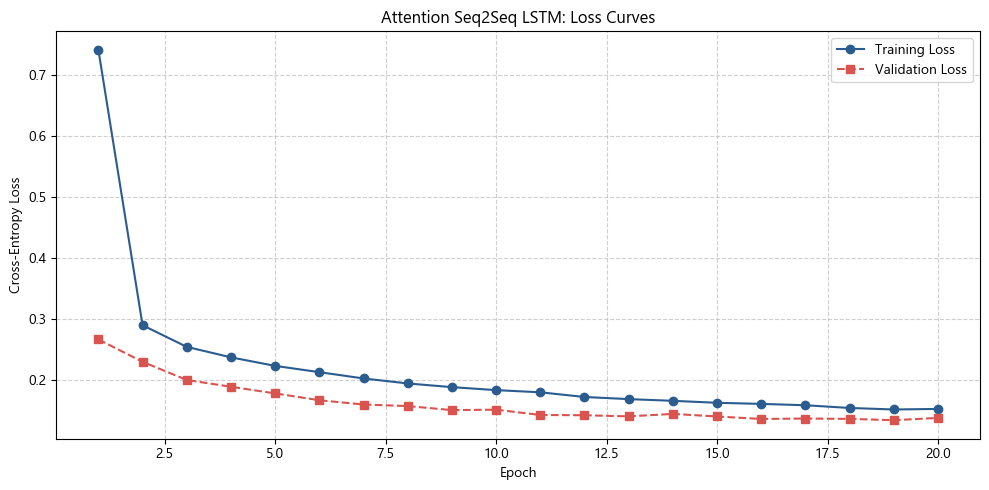

In [16]:
plt.figure(figsize=(10, 5))
epochs_range = range(1, len(history["train_loss"]) + 1)
plt.plot(epochs_range, history["train_loss"], "o-", label="Training Loss", color="#2b5c8f")
plt.plot(epochs_range, history["val_loss"], "s--", label="Validation Loss", color="#d9534f")
plt.title("Attention Seq2Seq LSTM: Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## 5. Conservative Sentence-Level Inference

Known vocabulary words are preserved. For an out-of-vocabulary word, the model generates a candidate; the candidate is accepted only when each Telugu word in the output is present in the project's vocabulary. This reduces unsupported outputs. A correction can contain a space when it repairs a synthetic missing-space example.

In [17]:
class FastDictionaryDetector:
    def __init__(self, vocab):
        self.vocab = vocab
        self.telugu_pattern = re.compile(r"[\u0C00-\u0C7F]")
        self.punctuation_pattern = re.compile(r"^[^\u0C00-\u0C7F\w]+|[^\u0C00-\u0C7F\w]+$", re.UNICODE)

    def clean(self, token):
        return self.punctuation_pattern.sub("", token).strip()

    def is_error(self, token):
        cleaned = self.clean(token)
        return bool(cleaned and self.telugu_pattern.search(cleaned) and cleaned not in self.vocab)


detector = FastDictionaryDetector(vocab_set)


def predict_word_lstm(model, word, max_len=MAX_WORD_LEN):
    model.eval()
    with torch.no_grad():
        source_ids = [SOS_IDX] + [char2idx.get(char, UNK_IDX) for char in word[:max_len - 2]] + [EOS_IDX]
        src = torch.tensor([source_ids], dtype=torch.long, device=DEVICE)
        encoder_outputs, hidden, cell = model.encoder(src)
        src_mask = src.ne(PAD_IDX)
        token = torch.tensor([[SOS_IDX]], dtype=torch.long, device=DEVICE)
        predicted = []
        for _ in range(max_len):
            logits, hidden, cell = model.decoder(token, hidden, cell, encoder_outputs, src_mask)
            token_id = logits.argmax(dim=1).item()
            if token_id == EOS_IDX:
                break
            if token_id not in (PAD_IDX, SOS_IDX, UNK_IDX):
                predicted.append(idx2char.get(token_id, ""))
            token = torch.tensor([[token_id]], dtype=torch.long, device=DEVICE)
        return "".join(predicted)


def is_supported_correction(candidate):
    candidate_words = candidate.split()
    return bool(candidate_words) and all(
        (word in vocab_set) or not re.search(r"[\u0C00-\u0C7F]", word)
        for word in candidate_words
    )


def predict_sentence_lstm(model, sentence, detector=detector):
    corrected_tokens = []
    for token in sentence.split():
        core = detector.clean(token)
        if not core or not detector.is_error(token):
            corrected_tokens.append(token)
            continue
        candidate = predict_word_lstm(model, core)
        if candidate and is_supported_correction(candidate):
            corrected_tokens.append(token.replace(core, candidate, 1))
        else:
            corrected_tokens.append(token)
    return " ".join(corrected_tokens)


canonical_inputs = [
    "తేలుగు భాశ చాల అందమైణది",
    "విద్యార్ధులు రేపు పరిక్షలు రాసారు",
    "భారతదేశం ఒక గొప్ప ప్రజాస్వామ్య దేశం",
]
for text in canonical_inputs:
    print(f"Input     : {text}")
    print(f"Corrected : {predict_sentence_lstm(model, text)}\n")

Input     : తేలుగు భాశ చాల అందమైణది
Corrected : తెలుగు భాష చాల అందమైనది

Input     : విద్యార్ధులు రేపు పరిక్షలు రాసారు
Corrected : విద్యార్ధులు రేపు పరీక్షలు రాసారు

Input     : భారతదేశం ఒక గొప్ప ప్రజాస్వామ్య దేశం
Corrected : భారతదేశం ఒక గొప్ప ప్రజాస్వామ్య దేశం



---
## 6. Test Evaluation

The complete sentence-level test slice is evaluated with the same WER, CER, exact match, BLEU, token precision/recall/F1, and throughput metrics used in the earlier project notebook. This is still an automatic benchmark; inspect the examples and per-error results before drawing conclusions about real-world quality.

In [18]:
def compute_metrics(predictions: list, references: list) -> dict:
    """Computes standard text correction evaluation metrics."""
    if not predictions or not references or len(predictions) != len(references):
        return {}

    wer = jiwer.wer(references, predictions)
    cer = jiwer.cer(references, predictions)
    exact_matches = sum(1 for p, r in zip(predictions, references) if p.strip() == r.strip())
    exact_match_acc = exact_matches / len(predictions)
    
    try:
        bleu = sacrebleu.corpus_bleu(predictions, [references])
        bleu_score = bleu.score
    except Exception:
        bleu_score = 0.0
        
    total_tp = 0
    total_pred_tokens = 0
    total_ref_tokens = 0
    
    for p, r in zip(predictions, references):
        p_toks = p.split()
        r_toks = r.split()
        c_pred = Counter(p_toks)
        c_ref = Counter(r_toks)
        total_tp += sum((c_pred & c_ref).values())
        total_pred_tokens += len(p_toks)
        total_ref_tokens += len(r_toks)
        
    precision = (total_tp / total_pred_tokens) if total_pred_tokens > 0 else 0.0
    recall = (total_tp / total_ref_tokens) if total_ref_tokens > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    return {
        "WER": wer, "CER": cer, "ExactMatch": exact_match_acc,
        "BLEU": bleu_score, "Precision": precision, "Recall": recall,
        "F1": f1, "Total_Samples": len(predictions)
    }

# Take 1,000 test evaluation slice
EVAL_SIZE = 1000
eval_slice = test_data[:EVAL_SIZE]
eval_inputs = [item['input'] for item in eval_slice]
eval_targets = [item['target'] for item in eval_slice]

print(f"Running Seq2Seq LSTM inference on {len(eval_slice):,} test sentences...")
t_start = time.time()
lstm_predictions = []
for s in tqdm(eval_inputs, desc="Seq2Seq LSTM Inference"):
    lstm_predictions.append(predict_sentence_lstm(model, s, detector=detector))
t_elapsed = time.time() - t_start

# Compute Metrics
m_lstm = compute_metrics(lstm_predictions, eval_targets)
m_lstm["Inference_Time_Sec"] = t_elapsed
m_lstm["Sentences_Per_Sec"] = len(eval_inputs) / t_elapsed if t_elapsed > 0 else 0

print("\n--- Seq2Seq LSTM Performance Metrics ---")
print(f"  WER (Word Error Rate)  : {m_lstm['WER']:.4f}")
print(f"  CER (Char Error Rate)  : {m_lstm['CER']:.4f}")
print(f"  Exact Match Accuracy   : {m_lstm['ExactMatch']*100:.2f}%")
print(f"  BLEU Score             : {m_lstm['BLEU']:.2f}")
print(f"  Token Precision        : {m_lstm['Precision']*100:.2f}%")
print(f"  Token Recall           : {m_lstm['Recall']*100:.2f}%")
print(f"  Token F1 Score         : {m_lstm['F1']*100:.2f}%")
print(f"  Throughput Speed       : {m_lstm['Sentences_Per_Sec']:.1f} sentences/sec")


Running Seq2Seq LSTM inference on 1,000 test sentences...


Seq2Seq LSTM Inference:   0%|          | 0/1000 [00:00<?, ?it/s]


--- Seq2Seq LSTM Performance Metrics ---
  WER (Word Error Rate)  : 0.0831
  CER (Char Error Rate)  : 0.0113
  Exact Match Accuracy   : 53.60%
  BLEU Score             : 83.66
  Token Precision        : 92.28%
  Token Recall           : 91.80%
  Token F1 Score         : 92.04%
  Throughput Speed       : 35.4 sentences/sec


---
## 7. Master Benchmark Results Table (Baselines vs Seq2Seq LSTM)

We integrate the prior baseline results from **Notebook 03** with our **Seq2Seq LSTM Neural Model** into a master performance comparison table.


In [19]:
# Baseline benchmark results from Notebook 03
master_benchmark = {
    "Uncorrected Baseline": {
        "WER": 0.1838, "CER": 0.0270, "ExactMatch": 0.1860, "BLEU": 64.75,
        "Precision": 0.8242, "Recall": 0.8162, "F1": 0.8202, "Speed": "N/A (Instant)"
    },
    "Rule-Based Corrector": {
        "WER": 0.1128, "CER": 0.0180, "ExactMatch": 0.3390, "BLEU": 77.53,
        "Precision": 0.8958, "Recall": 0.8872, "F1": 0.8915, "Speed": "1556.0"
    },
    "Dictionary + Edit Distance": {
        "WER": 0.1269, "CER": 0.0223, "ExactMatch": 0.3530, "BLEU": 75.42,
        "Precision": 0.8816, "Recall": 0.8731, "F1": 0.8773, "Speed": "9.6"
    },
    "Hybrid (Rule + Edit Distance)": {
        "WER": 0.1212, "CER": 0.0214, "ExactMatch": 0.3750, "BLEU": 76.53,
        "Precision": 0.8873, "Recall": 0.8788, "F1": 0.8830, "Speed": "14.8"
    },
    "Seq2Seq LSTM Neural Model (Ours)": {
        "WER": m_lstm["WER"], "CER": m_lstm["CER"], "ExactMatch": m_lstm["ExactMatch"], "BLEU": m_lstm["BLEU"],
        "Precision": m_lstm["Precision"], "Recall": m_lstm["Recall"], "F1": m_lstm["F1"],
        "Speed": f"{m_lstm['Sentences_Per_Sec']:.1f}"
    }
}

rows_master = []
for name, m in master_benchmark.items():
    rows_master.append({
        "Model / Approach": name,
        "WER (↓)": f"{m['WER']:.4f}",
        "CER (↓)": f"{m['CER']:.4f}",
        "Exact Match (↑)": f"{m['ExactMatch']*100:.2f}%",
        "BLEU (↑)": f"{m['BLEU']:.2f}",
        "Precision (↑)": f"{m['Precision']*100:.2f}%",
        "Recall (↑)": f"{m['Recall']*100:.2f}%",
        "F1 Score (↑)": f"{m['F1']*100:.2f}%",
        "Throughput (sent/s)": m['Speed']
    })

df_master = pd.DataFrame(rows_master)
print("=" * 110)
print("       TELUGU TEXT CORRECTION — MASTER BENCHMARK COMPARISON (BASELINES VS SEQ2SEQ LSTM)")
print("=" * 110)
display(df_master)
print("=" * 110)


       TELUGU TEXT CORRECTION — MASTER BENCHMARK COMPARISON (BASELINES VS SEQ2SEQ LSTM)


,Model / Approach,WER (↓),CER (↓),Exact Match (↑),BLEU (↑),Precision (↑),Recall (↑),F1 Score (↑),Throughput (sent/s)
0,Uncorrected Baseline,0.1838,0.0270,18.60%,64.75,82.42%,81.62%,82.02%,N/A (Instant)
1,Rule-Based Corrector,0.1128,0.0180,33.90%,77.53,89.58%,88.72%,89.15%,1556.0
2,Dictionary + Edit Distance,0.1269,0.0223,35.30%,75.42,88.16%,87.31%,87.73%,9.6
3,Hybrid (Rule + Edit Distance),0.1212,0.0214,37.50%,76.53,88.73%,87.88%,88.30%,14.8
4,Seq2Seq LSTM Neural Model (Ours),0.0831,0.0113,53.60%,83.66,92.28%,91.80%,92.04%,35.4


---
## 8. Graphical Performance Visualizations

We plot comparative bar charts illustrating the relative strengths of the Seq2Seq LSTM model compared to the prior baselines.


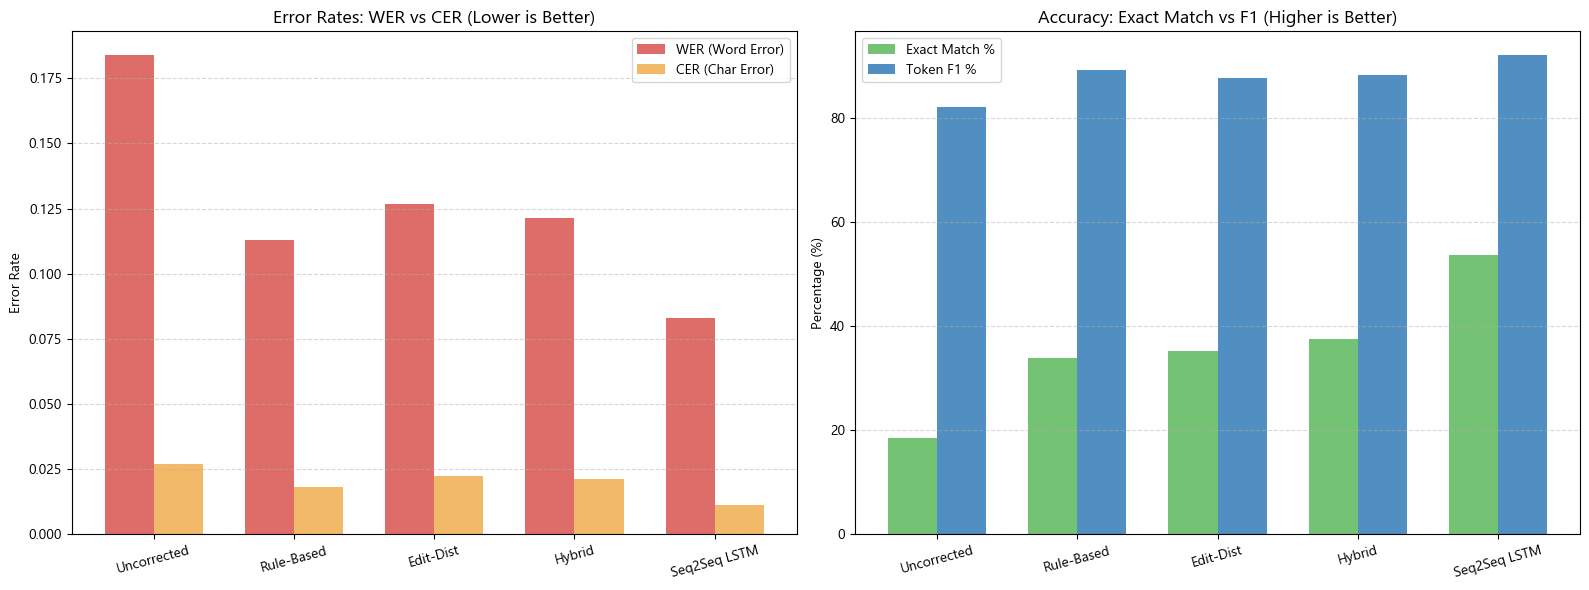

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_list = list(master_benchmark.keys())
short_labels = ["Uncorrected", "Rule-Based", "Edit-Dist", "Hybrid", "Seq2Seq LSTM"]

# 1. Error Rates Comparison (WER & CER)
wers = [master_benchmark[m]["WER"] for m in models_list]
cers = [master_benchmark[m]["CER"] for m in models_list]
x = np.arange(len(short_labels))
width = 0.35

axes[0].bar(x - width/2, wers, width, label='WER (Word Error)', color='#d9534f', alpha=0.85)
axes[0].bar(x + width/2, cers, width, label='CER (Char Error)', color='#f0ad4e', alpha=0.85)
axes[0].set_title('Error Rates: WER vs CER (Lower is Better)', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels, rotation=15)
axes[0].set_ylabel('Error Rate')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Accuracy Comparison (Exact Match & F1 Score)
ems = [master_benchmark[m]["ExactMatch"] * 100 for m in models_list]
f1s = [master_benchmark[m]["F1"] * 100 for m in models_list]

axes[1].bar(x - width/2, ems, width, label='Exact Match %', color='#5cb85c', alpha=0.85)
axes[1].bar(x + width/2, f1s, width, label='Token F1 %', color='#337ab7', alpha=0.85)
axes[1].set_title('Accuracy: Exact Match vs F1 (Higher is Better)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_labels, rotation=15)
axes[1].set_ylabel('Percentage (%)')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 9. Qualitative Evaluation & Side-by-Side Analysis

We examine 15 representative test sentences to evaluate qualitative performance:
- `✅ Perfect`: Sentence completely restored to ground truth.
- `⚠️ Partial`: Typographical error partially repaired.
- `❌ Unfixed`: Error left uncorrected.


In [21]:
print("=== QUALITATIVE TEST PREDICTIONS (SAMPLE EVALUATION) ===\n")

qual_records = []
for i in range(15):
    inp = eval_inputs[i]
    tgt = eval_targets[i]
    pred = lstm_predictions[i]
    err_type = eval_slice[i]['error_type']
    
    if pred == tgt:
        status = "✅ Perfect"
    elif pred == inp:
        status = "❌ Unfixed"
    else:
        status = "⚠️ Partial"
        
    qual_records.append({
        "Index": i + 1,
        "Error Type": err_type,
        "Corrupted Input": inp,
        "LSTM Output": pred,
        "Ground Truth": tgt,
        "Status": status
    })

for r in qual_records:
    print(f"[{r['Index']}] Status: {r['Status']} | Error Type: {r['Error Type']}")
    print(f"  Input  : {r['Corrupted Input']}")
    print(f"  Output : {r['LSTM Output']}")
    print(f"  Target : {r['Ground Truth']}\n")


=== QUALITATIVE TEST PREDICTIONS (SAMPLE EVALUATION) ===

[1] Status: ✅ Perfect | Error Type: none
  Input  : వాడ్రేవు చినవీరభద్రుడు
  Output : వాడ్రేవు చినవీరభద్రుడు
  Target : వాడ్రేవు చినవీరభద్రుడు

[2] Status: ✅ Perfect | Error Type: none
  Input  : 1999లో అత్యున్నత పురస్కారం భారతరత్న
  Output : 1999లో అత్యున్నత పురస్కారం భారతరత్న
  Target : 1999లో అత్యున్నత పురస్కారం భారతరత్న

[3] Status: ✅ Perfect | Error Type: matra,swap
  Input  : భారతదేశములో మొత్తం 50 రకాల అరటిపండ్లు లభిస్తున్నాయి
  Output : భారతదేశములో మొత్తం 50 రకాల అరటిపండ్లు లభిస్తున్నాయి
  Target : భారతదేశములో మొత్తం 50 రకాల అరటిపండ్లు లభిస్తున్నాయి

[4] Status: ✅ Perfect | Error Type: none
  Input  : డి కోర్సులను అందిస్తున్నాయి
  Output : డి కోర్సులను అందిస్తున్నాయి
  Target : డి కోర్సులను అందిస్తున్నాయి

[5] Status: ❌ Unfixed | Error Type: space
  Input  : పూ 400 వరకు ఉపనిషత్తులకూర్చబడ్డాయి
  Output : పూ 400 వరకు ఉపనిషత్తులకూర్చబడ్డాయి
  Target : పూ 400 వరకు ఉపనిషత్తుల కూర్చబడ్డాయి

[6] Status: ✅ Perfect | Error Type: m

---
## 10. Interpretation and Limitations

- Attention and broader training data should help the character model learn noisy-to-clean mappings more reliably than the original small, truncated sample.
- This model predicts each out-of-vocabulary token independently. It cannot reliably repair grammar or use sentence meaning to choose between valid words.
- The vocabulary gate avoids many unsupported outputs but also prevents changing an erroneous form that is itself in the vocabulary.
- Compare this model and the rule-based corrector on the same held-out sentence pairs before deciding which is better. The reported baseline values from another notebook are not a substitute for recomputing both systems on the exact same slice.

---
*End of Notebook 04 — Attention-Based Character Seq2Seq LSTM*

In [22]:
model

AttentiveSeq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(231, 96, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (lstm): LSTM(96, 192, batch_first=True)
  )
  (decoder): AttentionDecoder(
    (embedding): Embedding(231, 96, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (attn_encoder): Linear(in_features=192, out_features=192, bias=False)
    (attn_decoder): Linear(in_features=192, out_features=192, bias=False)
    (attn_score): Linear(in_features=192, out_features=1, bias=False)
    (lstm): LSTM(288, 192, batch_first=True)
    (output): Linear(in_features=384, out_features=231, bias=True)
  )
)

In [23]:
torch.save(model.state_dict(), "LSTM_MODEL.pth")

In [24]:
loaded_model = torch.load("LSTM_MODEL.pth", map_location=DEVICE)

In [26]:
loaded_model = AttentiveSeq2Seq(encoder, decoder, DEVICE).to(DEVICE)
loaded_model.load_state_dict(torch.load("LSTM_MODEL.pth", map_location=DEVICE))

<All keys matched successfully>